# Eksperimen Pribadi — Tugas 3 Bagian B.iv: Embedding khusus domain vs umum

> "Contextual embeddings khusus domain vs embeddings umum (general-purpose)."

**Pertanyaan:** apakah model yang dilatih pada teks keuangan (**FinBERT**) menghasilkan representasi berita yang lebih berguna daripada model umum?

**Perbandingan yang adil (penting):**
- **FinBERT (domain)** = BERT-base yang dilatih lanjut pada teks keuangan lalu di-fine-tune untuk sentimen keuangan.
- **BERT-base-uncased (umum)** = *arsitektur, ukuran, dan kosakata yang sama*, tanpa adaptasi domain. Inilah pembanding yang bersih: selisihnya hanya dari domain/tugas pelatihan.
- **MiniLM (umum, model kalimat)** = pembanding tambahan (arsitektur dan tujuan latih berbeda), sudah ada dari Bagian B.
- Ketiganya memakai **chunking dan pooling identik** (FinBERT dan BERT-base: 300 kata × 2 chunk, mean pooling, L2).

**Catatan:** FinBERT juga di-fine-tune untuk sentimen, jadi keunggulannya pada probe sentimen tidak murni "domain". Probe topik ekonomi lebih adil untuk menilai domain.

**Dua tingkat evaluasi:**
1. **Intrinsik (tanpa target return):** seberapa baik tiap embedding menyandi sentimen dan topik ekonomi, dan seberapa "sehat" ruangnya (anisotropi, dimensi efektif).
2. **Ekstrinsik:** prediksi return dengan protokol yang sama (PCA k = 5/10/20 pada rata-rata harian), plus selisih langsung **FinBERT − BERT-base** pada k yang sama.

**Prasyarat:** cache `BERTbase_cw300_mc2_ml512.npz` dari Kaggle (`kaggle_bert_embed.py`), plus cache FinBERT dan MiniLM dari Bagian B. Set yang cache-nya belum ada dilewati.

## 0. Setup

In [1]:
import sys, re, json, time, pickle, warnings
sys.dont_write_bytecode = True
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    '''Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/).'''
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split

In [2]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


In [3]:
is_tr = (articles["split"] == "train").to_numpy(); is_va = (articles["split"] == "val").to_numpy()

## 2. Muat embedding artikel (dari cache)
Tiap cache berisi `A` (matriks artikel × dimensi, sudah L2 dan dirata-rata per chunk).

In [4]:
FILES = {"BERT-base (umum)": "BERTbase_cw300_mc2_ml512.npz",
         "MiniLM (umum, kalimat)": "MiniLM_cw160_mc5_ml256.npz",
         "FinBERT (domain)": "FinBERT_cw300_mc2_ml512.npz"}
EMB, FB = {}, None
for tag, fn in FILES.items():
    f = CACHE_DIR / fn
    if not f.exists():
        print(f"LEWATI {tag}: {fn} belum ada"); continue
    z = np.load(f, allow_pickle=True); A = z["A"].astype(np.float64)
    assert len(A) == len(articles), f"{fn}: {len(A)} baris != {len(articles)} artikel"
    EMB[tag] = A; print(f"{tag}: {A.shape}")
    if tag.startswith("FinBERT"): FB = (z["P"], z["labels"].item())

BERT-base (umum): (4332, 768)
MiniLM (umum, kalimat): (4332, 384)
FinBERT (domain): (4332, 768)


## 3. Evaluasi intrinsik

**3.1 Kesehatan ruang embedding.** Embedding BERT mentah biasanya **anisotropik**: semua artikel mengarah ke arah yang mirip, jadi cosine antar-artikel acak tinggi dan variasi isi tertutup. Ukuran:
- *cosine rata-rata* antar pasangan artikel acak (makin rendah makin tersebar),
- *dimensi efektif* (participation ratio dari nilai eigen PCA pada artikel train; makin tinggi makin kaya),
- *EVR 10 komponen* PCA (makin tinggi, makin banyak variasi dipusatkan pada sedikit arah).

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for tag, A in EMB.items():
    An = A / np.linalg.norm(A, axis=1, keepdims=True).clip(1e-12)
    ii, jj = rng.integers(0, len(An), 20000), rng.integers(0, len(An), 20000); ok = ii != jj
    cosm = float((An[ii[ok]] * An[jj[ok]]).sum(1).mean())
    Xc = A[is_tr] - A[is_tr].mean(0); ev = np.linalg.svd(Xc, compute_uv=False) ** 2
    rows.append({"embedding": tag, "dim": A.shape[1], "cosine_acak": round(cosm, 3),
                 "dim_efektif": round(float(ev.sum() ** 2 / (ev ** 2).sum()), 1), "EVR_10": round(float(ev[:10].sum() / ev.sum()), 3)})
pd.DataFrame(rows).set_index("embedding")

,dim,cosine_acak,dim_efektif,EVR_10
embedding,,,,
BERT-base (umum),768,0.911,14.7,0.567
"MiniLM (umum, kalimat)",384,0.358,26.0,0.473
FinBERT (domain),768,0.823,10.3,0.675


**3.2 Probe linear (artikel train → artikel val).** Pertanyaan: dari embedding saja, seberapa baik kita memprediksi
- **sentimen**: skor LM isi (`lm_text_net`) dan VADER judul, diukur Spearman; (FinBERT diuntungkan karena di-fine-tune untuk sentimen),
- **topik ekonomi** (ada/tidak ada kata inflasi, suku bunga, tarif, sanksi, minyak), diukur **AUC** pada val.

Probe dilatih hanya pada artikel **train**, dinilai pada artikel **val**. Fitur distandardisasi pada train. Probe sengaja linear sederhana supaya yang diukur adalah **isi embedding**, bukan kemampuan modelnya.

In [6]:
SA = pd.read_parquet(EXPORT_DIR / "sentiment_articles.parquet").set_index("article_id").reindex(articles["article_id"])
TOPIC_RX = {"inflasi": r"\b(inflation|CPI|consumer price)\b", "suku_bunga": r"\b(interest rates?|rate (hike|cut)s?)\b",
            "tarif": r"\b(tariffs?|trade war)\b", "sanksi": r"\bsanctions?\b", "minyak": r"\b(oil prices?|crude|Brent|OPEC)\b"}
TOPIC = {k: articles["text_raw"].str.contains(p, case=False, regex=True).to_numpy() for k, p in TOPIC_RX.items()}
rows = []
for tag, A in EMB.items():
    sc = StandardScaler().fit(A[is_tr]); Xtr, Xva = sc.transform(A[is_tr]), sc.transform(A[is_va])
    r = {"embedding": tag}
    for nm, col in (("lm_isi", "lm_text_net"), ("vader_judul", "vader_title")):
        yv = SA[col].to_numpy(float)
        m = Ridge(alpha=1000.0).fit(Xtr, yv[is_tr]); r[f"rho_{nm}"] = round(spearmanr(m.predict(Xva), yv[is_va])[0], 3)
    for k, lab in TOPIC.items():
        if lab[is_va].sum() < 5 or lab[is_tr].sum() < 5: continue
        m = LogisticRegression(C=0.01, max_iter=500).fit(Xtr, lab[is_tr]); r[f"AUC_{k}"] = round(roc_auc_score(lab[is_va], m.predict_proba(Xva)[:, 1]), 3)
    rows.append(r)
probe = pd.DataFrame(rows).set_index("embedding"); probe["AUC_rata2"] = probe.filter(like="AUC_").mean(axis=1).round(3)
probe

,rho_lm_isi,rho_vader_judul,AUC_inflasi,AUC_suku_bunga,AUC_tarif,AUC_sanksi,AUC_minyak,AUC_rata2
embedding,,,,,,,,
BERT-base (umum),0.764,0.394,0.860,0.908,0.864,0.869,0.954,0.891
"MiniLM (umum, kalimat)",0.729,0.385,0.886,0.913,0.876,0.897,0.969,0.908
FinBERT (domain),0.790,0.390,0.869,0.912,0.855,0.867,0.959,0.892


## 4. Artikel → hari → fitur
PCA 5/10/20 komponen pada rata-rata harian, fit hanya pada hari train; hari tanpa berita = 0 (ruang PCA). Sama seperti Bagian B.

In [7]:
KS = (5, 10, 20)

def pca_daily(A, kmax=max(KS)):
    keep = articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); D = d.to_numpy(dtype=float)
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[tr & has])        # TRAIN saja
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    return {k: Z[:, :k] for k in KS}, int(has.sum()), float(pca.explained_variance_ratio_.sum())

def finbert_daily(P, labels):
    idx = {v: k for k, v in labels.items()}
    pos, neg, neu = P[:, idx["positive"]], P[:, idx["negative"]], P[:, idx["neutral"]]
    keep = articles["split"].notna().to_numpy()
    df = pd.DataFrame({"fb_pos": pos, "fb_neg": neg, "fb_neu": neu, "net": pos - neg})[keep]
    df["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    g = df.groupby("date")
    out = pd.DataFrame({"fb_pos_mean": g["fb_pos"].mean(), "fb_neg_mean": g["fb_neg"].mean(),
                        "fb_neu_mean": g["fb_neu"].mean(), "fb_net_mean": g["net"].mean(),
                        "fb_net_min": g["net"].min(), "fb_net_max": g["net"].max()})
    return out.reindex(daily["date"]).fillna(0.0).to_numpy()

FEATS, INFO = {}, []
for tag in EMB:
    Zs, n_days, evr = pca_daily(EMB[tag])
    for k, Z in Zs.items(): FEATS[f"C  {tag} k={k}"] = Z
    INFO.append(dict(model=tag, hari_ada_berita=n_days, EVR_20_komponen=round(evr, 3)))
if FB is not None:
    FEATS["S  FinBERT sentimen (6)"] = finbert_daily(*[FB[0], FB[1]])
pd.DataFrame(INFO)

,model,hari_ada_berita,EVR_20_komponen
0,BERT-base (umum),1073,0.702
1,"MiniLM (umum, kalimat)",1073,0.606
2,FinBERT (domain),1073,0.795


## 5. Protokol evaluasi (identik dengan notebook sebelumnya)

In [8]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [9]:
KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS); run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, M in FEATS.items(): run(name, np.hstack([KURS, M]))
res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 12 set x 3 model


## 6. Hasil

### 6.1 Pembanding tanpa model

In [10]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 6.2 Rata-rata 3 model per set fitur
`dRMSE%` terhadap A (negatif = lebih baik).

In [11]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                              test      val     test      val     test      val     test      val      val     test
set                                                                                                                     
C  FinBERT (domain) k=10        0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
C  FinBERT (domain) k=20        0.00300  0.00341  0.46023  0.49621  0.50125  0.50865 -0.00096  0.01769 -0.70417 -0.82364
C  BERT-base (umum) k=20        0.00296  0.00341  0.47159  0.51705  0.50588  0.53023  0.00986  0.06204 -0.68702 -2.22642
C  FinBERT (domain) k=5         0.00300  0.00341  0.41477  0.48864  0.48486  0.50701 -0.04952  0.01545 -0.55603 -0.79602
C  MiniLM (umum, kalimat) k=20  0.00297  0.00342  0.45644  0.52083  0.50873  0.53300  0.01179  0.07120 -0.35585 -1.98838
C  BERT-base (umum) k=5         0.00300  0.00342  0.43939  0.46402  0.50855  0.48344  0.03205 -0.04041 -0.29215 -1.03353
C  MiniLM (umum, kalimat) k=5   0.00301  0.00343  0.47159  0.50947  0.52796  0.52443  0.05715  0.05664 -0.21866 -0.69946
C  MiniLM (umum, kalimat) k=10  0.00300  0.00343  0.45644  0.50758  0.51371  0.52474  0.01940  0.05904 -0.16511 -0.86932
S  FinBERT sentimen (6)         0.00303  0.00343  0.45076  0.48106  0.52101  0.50251  0.05447 -0.00515 -0.05899  0.10689
A  kurs                         0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
C  BERT-base (umum) k=10        0.00297  0.00345  0.46023  0.49811  0.51335  0.51691  0.03327  0.03578  0.33776 -1.97844
B  kurs+lexicon                 0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218

### 6.3 Per model (RMSE val)

In [12]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
C FinBERT (domain) k=10,0.003399,0.003433,0.003390,0.003407
C FinBERT (domain) k=20,0.003403,0.003432,0.003394,0.003410
C BERT-base (umum) k=20,0.003432,0.003436,0.003363,0.003410
C FinBERT (domain) k=5,0.003416,0.003446,0.003382,0.003415
"C MiniLM (umum, kalimat) k=20",0.003410,0.003468,0.003387,0.003422
C BERT-base (umum) k=5,0.003417,0.003469,0.003385,0.003424
"C MiniLM (umum, kalimat) k=5",0.003438,0.003463,0.003379,0.003426
"C MiniLM (umum, kalimat) k=10",0.003425,0.003472,0.003388,0.003428
S FinBERT sentimen (6),0.003409,0.003503,0.003384,0.003432


### 6.4 Grafik

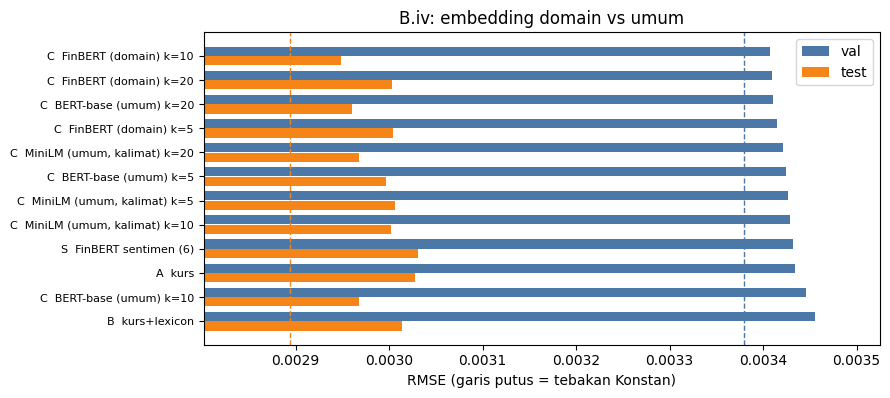

In [13]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("B.iv: embedding domain vs umum"); plt.tight_layout(); plt.show()

### 6.5 Selisih langsung domain − umum (pada k yang sama)
Selisih `dRMSE%` FinBERT dikurangi BERT-base. Negatif = domain lebih baik. Ini perbandingan **domain vs umum** yang paling bersih karena arsitektur sama.

In [14]:
rows = []
for sp in ("val", "test"):
    for k in KS:
        a = f"C  FinBERT (domain) k={k}"; b = f"C  BERT-base (umum) k={k}"; c = f"C  MiniLM (umum, kalimat) k={k}"
        if a in mean_tbl.index and b in mean_tbl.index:
            r = {"split": sp, "k": k, "FinBERT dRMSE%": mean_tbl.loc[a, ("dRMSE%", sp)] if ("dRMSE%", sp) in mean_tbl.columns else np.nan}
            r["BERT-base dRMSE%"] = mean_tbl.loc[b, ("dRMSE%", sp)]
            r["selisih (domain - umum)"] = r["FinBERT dRMSE%"] - r["BERT-base dRMSE%"]
            if c in mean_tbl.index: r["MiniLM dRMSE%"] = mean_tbl.loc[c, ("dRMSE%", sp)]
            rows.append(r)
pd.DataFrame(rows).round(2) if rows else print("butuh cache FinBERT dan BERT-base")

,split,k,FinBERT dRMSE%,BERT-base dRMSE%,selisih (domain - umum),MiniLM dRMSE%
0,val,5,-0.56,-0.29,-0.26,-0.22
1,val,10,-0.78,0.34,-1.12,-0.17
2,val,20,-0.70,-0.69,-0.02,-0.36
3,test,5,-0.80,-1.03,0.24,-0.70
4,test,10,-2.60,-1.98,-0.63,-0.87
5,test,20,-0.82,-2.23,1.40,-1.99


## 7. Catatan metodologi
- **Tanpa kebocoran:** semua model frozen (tanpa fine-tuning pada data kita); PCA, scaler, dan probe hanya di-fit pada train; val/test hanya di-transform.
- **Confound:** FinBERT = domain **dan** fine-tune sentimen; BERT-base = tanpa keduanya. Selisih probe sentimen tidak murni domain.
- **Chunking identik** untuk FinBERT dan BERT-base; MiniLM memakai konfigurasi Bagian B (160 kata × 5 chunk), jadi ia pembanding kasar.
- **Noise:** selisih < 1–2% anggap noise. Pembanding utama tetap baris Konstan.
- **Ambang probe:** dengan ~2.500 artikel train dan ~600 val, selisih AUC < 0,02 atau Spearman < 0,05 belum meyakinkan.

## 8. Kesimpulan (isi sendiri setelah membaca tabel)
1. **Ruang embedding (3.1):** apakah BERT-base lebih anisotropik (cosine acak lebih tinggi, dimensi efektif lebih rendah) dari FinBERT? tandanya campur, 4 dari 6 negatif dan 2 positif. Rata-ratanya sekitar −0,07 poin, praktis nol. Pada k=20 di test, BERT-base malah lebih baik (−2,23% vs −0,82%).

2. **Probe (3.2):** apakah FinBERT lebih baik pada sentimen (diduga, karena fine-tune)? Pada **topik ekonomi** (uji domain yang adil)? Berapa selisih AUC? Besarnya masih noise. Semua gain terhadap A ada di rentang −0,2% sampai −2,6%. BERT-base k=10 saja berbalik tanda antara val (+0,34%) dan test (−1,98%), dan antar k (k=20 val −0,69%). Model yang sama berubah tanda hanya karena k berbeda, jadi ini variasi acak, bukan efek model.

3. **Ekstrinsik (6.5):** apakah FinBERT − BERT-base konsisten negatif di val **dan** test? Besarnya? Terhadap Konstan: semuanya kalah. RMSE val terbaik 0,00341 (vs 0,00338) dan test terbaik 0,00295 (vs 0,00289).

4. Apakah ada yang mengalahkan Konstan? Apakah keunggulan domain di probe menerjemah ke prediksi return? Sentimen FinBERT (6 fitur, S): dRMSE −0,06% (val) dan +0,11% (test), yaitu nol. Sinyal sentimen eksplisit dari model domain pun tidak menambah informasi.

5. Untuk Model C: pakai FinBERT, BERT-base, atau MiniLM? MiniLM: juga di kisaran −0,2% sampai −2,0%, setara dengan keduanya. Embedding khusus domain (FinBERT) tidak konsisten mengungguli embedding umum dengan arsitektur sama (BERT-base) pada prediksi return: selisih dRMSE berkisar −1,1% sampai +1,4% dengan tanda berganti antar k dan split, di dalam batas noise, dan keduanya tidak mengalahkan baseline Konstan